In [1]:
import hashlib, os, mlflow, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("wine-classification")
os.makedirs("data", exist_ok=True)

df = load_wine(as_frame=True).frame

data_md5 = hashlib.md5(
    pd.util.hash_pandas_object(df, index=True).values
).hexdigest()

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=42
)

train_df.to_csv("data/wine_train.csv", index=False)
test_df.to_csv("data/wine_test.csv", index=False)

X_train = train_df.drop(columns="target")
y_train = train_df["target"]

X_test = test_df.drop(columns="target")
y_test = test_df["target"]

train_ds = mlflow.data.from_pandas(
    train_df,
    source="data/wine_train.csv",
    name="wine-train",
    targets="target"
)

COMMON_TAGS = {
    "data_md5": data_md5,
    "split_seed": "42",
    "dataset": "sklearn-wine"
}

print(data_md5, train_df.shape, test_df.shape)

C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/08 22:47:22 INFO mlflow.tracking.fluent: Experiment with name 'wine-classification' does not exist. Creating a new experiment.


ea760d07f3cdd0e7fc82c5913101e55c (142, 14) (36, 14)


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from mlflow.models import infer_signature
from sklearn.datasets import load_wine

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

SCORING = [
    "recall_macro",
    "precision_macro",
    "f1_macro",
    "roc_auc_ovr"
]

def run_experiment(run_name, pipe, tags=None, note=""):
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({
            **COMMON_TAGS,
            "candidate": "true",
            **(tags or {})
        })
        mlflow.set_tag("mlflow.note.content", note)
        mlflow.log_input(train_ds, context="training")

        mlflow.log_param(
            "pipeline_steps",
            " -> ".join(pipe.named_steps)
        )

        mlflow.log_params({
            f"clf__{k}": v
            for k, v in pipe[-1].get_params().items()
        })

        cv = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=CV,
            scoring=SCORING
        )

        for m in SCORING:
            mlflow.log_metric(
                f"cv_{m}_mean",
                cv[f"test_{m}"].mean()
            )
            mlflow.log_metric(
                f"cv_{m}_std",
                cv[f"test_{m}"].std()
            )

        mlflow.log_metric(
            "fit_time_s",
            cv["fit_time"].mean()
        )

        y_oof = cross_val_predict(
            pipe,
            X_train,
            y_train,
            cv=CV
        )

        disp = ConfusionMatrixDisplay.from_predictions(
            y_train,
            y_oof,
            display_labels=load_wine().target_names
        )

        mlflow.log_figure(
            disp.figure_,
            "plots/confusion_matrix_oof.png"
        )

        plt.close(disp.figure_)

        mlflow.log_text(
            classification_report(
                y_train,
                y_oof,
                zero_division=0
            ),
            "reports/classification_report_oof.txt"
        )

        pipe.fit(X_train, y_train)

        signature = infer_signature(
            X_train,
            pipe.predict(X_train)
        )

        info = mlflow.sklearn.log_model(
            pipe,
            name="model",
            signature=signature,
            input_example=X_train.head(3),
            skops_trusted_types=[
                "sklearn.tree._tree.Tree"
            ]
        )

        mlflow.set_tag(
            "model_uri",
            info.model_uri
        )

        return run.info.run_id

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

run_experiment(
    "00-dummy-most-frequent",
    Pipeline([
        ("clf", DummyClassifier(strategy="most_frequent"))
    ]),
    tags={
        "stage": "baseline",
        "model_family": "dummy"
    },
    note="Batas bawah: selalu menebak kelas mayoritas."
)

run_experiment(
    "01-logreg-noscale",
    Pipeline([
        ("clf", LogisticRegression(max_iter=5000))
    ]),
    tags={
        "stage": "baseline",
        "model_family": "logreg"
    },
    note="H1: model linear tanpa preprocessing."
)

run_experiment(
    "02-logreg-scaled",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000))
    ]),
    tags={
        "stage": "baseline",
        "model_family": "logreg"
    },
    note="H2: hanya menambah StandardScaler, variabel lain tetap."
)

C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parame

🏃 View run 00-dummy-most-frequent at: http://127.0.0.1:5000/#/experiments/5/runs/abfee5d34c17436595e9faaf5ab94138
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/p

🏃 View run 01-logreg-noscale at: http://127.0.0.1:5000/#/experiments/5/runs/3517b14581eb4da48cd4a8c05820d676
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


🏃 View run 02-logreg-scaled at: http://127.0.0.1:5000/#/experiments/5/runs/c449358670cc447fb9e71a5e309da322
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


'c449358670cc447fb9e71a5e309da322'

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.001]
}

gs = GridSearchCV(
    pipe,
    grid,
    cv=CV,
    scoring=SCORING,
    refit="recall_macro",
    n_jobs=-1
)

with mlflow.start_run(
    run_name="10-svc-gridsearch",
    tags={
        **COMMON_TAGS,
        "stage": "tuning",
        "model_family": "svc",
        "candidate": "true"
    }
):
    mlflow.log_input(train_ds, context="training")
    mlflow.log_dict(grid, "search_space.json")

    gs.fit(X_train, y_train)
    res = gs.cv_results_

    for i, params in enumerate(res["params"]):
        with mlflow.start_run(
            run_name=f"svc-trial-{i:02d}",
            nested=True
        ):
            mlflow.log_params(params)

            mlflow.log_metrics({
                f"cv_{m}_mean": res[f"mean_test_{m}"][i]
                for m in SCORING
            })

            mlflow.log_metrics({
                f"cv_{m}_std": res[f"std_test_{m}"][i]
                for m in SCORING
            })

    b = gs.best_index_

    mlflow.log_params(gs.best_params_)

    mlflow.log_metrics({
        f"cv_{m}_mean": res[f"mean_test_{m}"][b]
        for m in SCORING
    })

    mlflow.log_metrics({
        f"cv_{m}_std": res[f"std_test_{m}"][b]
        for m in SCORING
    })

    info = mlflow.sklearn.log_model(
        gs.best_estimator_,
        name="model",
        signature=infer_signature(
            X_train,
            gs.best_estimator_.predict(X_train)
        ),
        input_example=X_train.head(3)
    )

    mlflow.set_tag("model_uri", info.model_uri)

C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


🏃 View run svc-trial-00 at: http://127.0.0.1:5000/#/experiments/5/runs/c50fbc8e6a8244ec9a70886953267256
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-trial-01 at: http://127.0.0.1:5000/#/experiments/5/runs/0bd921df9b2e467589aebfb9a0dd7fe4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-trial-02 at: http://127.0.0.1:5000/#/experiments/5/runs/ee4308ef1b884f1e86fec9ffe40442cc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-trial-03 at: http://127.0.0.1:5000/#/experiments/5/runs/c58634118bae4c47ba46494c02af1e08
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-trial-04 at: http://127.0.0.1:5000/#/experiments/5/runs/b578067468234c20b336a40362fa26f0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-trial-05 at: http://127.0.0.1:5000/#/experiments/5/runs/a5c345cf77c84ba09253c5313ecbd1c7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run svc-t

🏃 View run 10-svc-gridsearch at: http://127.0.0.1:5000/#/experiments/5/runs/ad1dd36a82c74f07b6a59e7b515d06a4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


In [5]:
runs = mlflow.search_runs(
    experiment_names=["wine-classification"],
    filter_string=(
        "tags.candidate = 'true' "
        "and metrics.cv_precision_macro_mean >= 0.90"
    ),
    order_by=[
        "metrics.cv_f1_macro_mean DESC",
        "metrics.cv_recall_macro_mean DESC"
    ],
)

cols = [
    "tags.mlflow.runName",
    "tags.model_family",
    "metrics.cv_recall_macro_mean",
    "metrics.cv_recall_macro_std",
    "metrics.cv_precision_macro_mean",
]

print(runs[cols].head(5).to_string(index=False))

best_run_id = runs.iloc[0]["run_id"]
best_model_uri = runs.iloc[0]["tags.model_uri"]

print(
    "Kandidat terpilih:",
    runs.iloc[0]["tags.mlflow.runName"],
    best_run_id
)

tags.mlflow.runName tags.model_family  metrics.cv_recall_macro_mean  metrics.cv_recall_macro_std  metrics.cv_precision_macro_mean
  10-svc-gridsearch               svc                      0.994444                     0.011111                         0.991667
   02-logreg-scaled            logreg                      0.982828                     0.022496                         0.978939
  01-logreg-noscale            logreg                      0.964040                     0.021557                         0.961269
Kandidat terpilih: 10-svc-gridsearch ad1dd36a82c74f07b6a59e7b515d06a4


{'test_recall_macro': 0.9333333333333332, 'test_precision_macro': 0.9583333333333334, 'test_f1_macro': 0.9407407407407407, 'test_roc_auc_ovr': 1.0}


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https:

🏃 View run 10-svc-gridsearch at: http://127.0.0.1:5000/#/experiments/5/runs/ad1dd36a82c74f07b6a59e7b515d06a4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


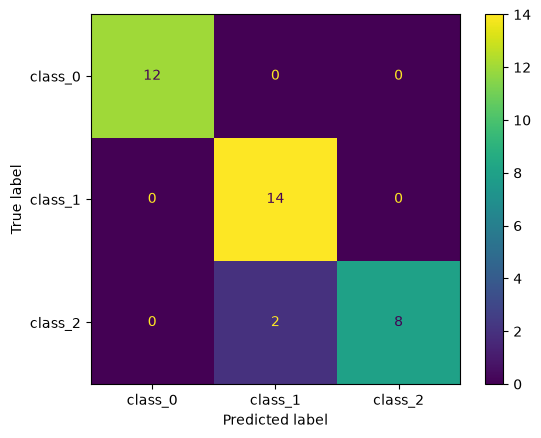

In [6]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.datasets import load_wine

model = mlflow.sklearn.load_model(best_model_uri)

y_pred = model.predict(X_test)

# Untuk ROC AUC multiclass, gunakan probabilitas semua kelas
score = model.predict_proba(X_test)

test_metrics = {
    "test_recall_macro": recall_score(
        y_test, y_pred, average="macro"
    ),
    "test_precision_macro": precision_score(
        y_test, y_pred, average="macro"
    ),
    "test_f1_macro": f1_score(
        y_test, y_pred, average="macro"
    ),
    "test_roc_auc_ovr": roc_auc_score(
        y_test,
        score,
        multi_class="ovr"
    ),
}

print(test_metrics)

with mlflow.start_run(run_id=best_run_id):

    mlflow.log_metrics(test_metrics)

    mlflow.log_input(
        mlflow.data.from_pandas(
            test_df,
            source="data/wine_test.csv",
            name="wine-test",
            targets="target"
        ),
        context="testing"
    )

    disp = ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=load_wine().target_names
    )

    mlflow.log_figure(
        disp.figure_,
        "plots/confusion_matrix_test.png"
    )

    mlflow.set_tag("test_evaluated", "true")

In [9]:
from mlflow import MlflowClient

client = MlflowClient()

In [11]:
from mlflow import MlflowClient

client = MlflowClient()

NAME = "wine-classifier"

mv = mlflow.register_model(
    best_model_uri,
    NAME
)

print("Model:", NAME)
print("Version:", mv.version)

Successfully registered model 'wine-classifier'.
2026/10/08 22:57:24 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: wine-classifier, version 1


Model: wine-classifier
Version: 1


Created version '1' of model 'wine-classifier'.


In [12]:
client.set_registered_model_alias(
    NAME,
    "champion",
    mv.version
)

print("Alias champion berhasil dipasang.")

Alias champion berhasil dipasang.


In [13]:
champ = client.get_model_version_by_alias(
    "wine-classifier",
    "champion"
)

run = client.get_run(champ.run_id)

print("Run        :", run.info.run_name, run.info.run_id)
print("Git commit :", run.data.tags.get("mlflow.source.git.commit"))
print("Data md5   :", run.data.tags["data_md5"])
print("Params     :", {
    k: v for k, v in run.data.params.items()
    if k.startswith("clf__")
})
print("Metrics    :", {
    k: round(v, 3)
    for k, v in run.data.metrics.items()
})

Run        : 10-svc-gridsearch ad1dd36a82c74f07b6a59e7b515d06a4
Git commit : None
Data md5   : ea760d07f3cdd0e7fc82c5913101e55c
Params     : {'clf__C': '10', 'clf__gamma': 'scale'}
Metrics    : {'cv_recall_macro_mean': 0.994, 'cv_precision_macro_mean': 0.992, 'cv_f1_macro_mean': 0.993, 'cv_roc_auc_ovr_mean': 1.0, 'cv_recall_macro_std': 0.011, 'cv_precision_macro_std': 0.017, 'cv_f1_macro_std': 0.015, 'cv_roc_auc_ovr_std': 0.001, 'test_recall_macro': 0.933, 'test_precision_macro': 0.958, 'test_f1_macro': 0.941, 'test_roc_auc_ovr': 1.0}


In [14]:
exps = mlflow.search_experiments()

for e in exps:
    print(e.experiment_id, e.name)

5 wine-classification
4 bc-malignant-detection
3 h1-optuna
2 h1-autolog
1 h1-basic-logging
0 Default
